# Discovering the 3-Point Line with Competitive Learning

Can a competitive learning network find the NBA 3-point line using only where shots were taken? This notebook trains one on shot locations from 2000-01 to 2024-25 and tracks how its map of the court changes as the league moved toward the 3.

**Contents**

- Objective, Model and Metrics
1. Data: counts, train and test split, heatmaps, shot distance, zone shares
2. Experiments 1 and 2: Finding the line in 2000-01 and 2024-25
3. Experiment 3: Sequential training across eras
4. Experiment 4: Polar inputs and the shape of the line
5. Limitations and possible improvements

## Objective

I want to see if a network can find the 3-point line using only where shots were taken. It's never told where the line is or which shots are threes.

Over the last 20 years, players stopped taking long twos. Shots now pile up at the rim and just behind the arc, which leaves a gap just inside the line. If the network puts cells behind the arc, and almost all of their shots are threes, then it found the line on its own.

I also check if it learns the shape of the line. The line is 22 ft away in the corners and 23.75 ft at the top. So if the network learned the shape, its corner cells should sit closer to the basket.

Last, I train one network on four seasons in order, from 2000-01 to 2024-25. This shows how its map of the court changes as the league moved toward the 3.

## Model

I used a single-layer competitive learning network in which each cell has two weights and can therefore be plotted as a point on the court.

Each shot comes in as its x and y position in feet, with the basket at (0, 0). The cell closest to the shot wins. Only the winner learns, and it moves a small step toward the shot. The other cells stay where they are. After many shots, each cell ends up in the middle of the shots it wins. I call that point its prototype.

I pick the winner by distance rather than by the largest net input. Net input only works when all weight vectors are the same length, and forcing that would erase each shot's distance from the basket.

I used 6 cells, one for each official NBA zone. They start at 6 random shots and train for 8 passes over 20,000 shots. The step size starts at 0.05 and gets smaller each pass so the cells settle down.

In Experiment 4 I also try polar inputs, which describe a shot by its distance from the basket and its position along the arc. With x and y inputs, the borders between cells are always straight lines, so no cell can follow the curve of the 3-point line. Polar inputs let those borders bend to follow the arc.

I chose this model because it learns groups without being given any labels. Cells gather where shots are dense, so the empty strip inside the 3-point line should split them into cells inside and behind it. It also learns one shot at a time, so a single network can keep learning season after season without starting over.

## Metrics

The network never sees shot type or zone, which are used only for scoring, mostly on games it never trained on.

- **Line-recovery accuracy** is my main metric. I label each cell a "2" or a "3" based on most of its training shots. Then I check that label on every test shot the cell wins. Long twos just inside the line count as mistakes.
- **Arc purity** looks at cells more than 20 ft out. It's the share of their shots that are threes. If it's near 100%, those cells are behind the line.
- **Cell allocation** counts how many cells end up near the rim (under 8 ft), in the mid-range (8 to 20 ft), and past 20 ft.
- **ARI** shows how close the network's regions are to the six official zones. 0 means chance and 1 means a perfect match.
- **Quantization error** is how far each test shot is from its closest prototype, on average.
- **Dead cells** are cells that never win a shot.
- **The shape test** compares how far the corner cells and the top-of-the-arc cells are from the basket.
- **For the eras**, I track how far each cell moves between seasons. I also track how the share of shots shifts between arc cells and mid-range cells. And I compare the final map to a network trained fresh on 2024-25.

I used three different baselines to compare against. One naively guesses the most common shot type, another uses k-means to find all the centers simultaneously, and the last simply uses random cells with no learning.

In [1]:
import os
import subprocess
import sys

REPO_URL = "https://github.com/BiyonWann/bballNeuro.git"

if "google.colab" in sys.modules:
    if not os.path.isdir("threept"):
        subprocess.run(["git", "clone", REPO_URL], check=True)
        os.chdir("bballNeuro")
    subprocess.run([sys.executable, "-m", "pip", "install", "-r", "requirements.txt"], check=True)
else:
    print("Not running in Colab, setup skipped")

Not running in Colab, setup skipped


In [2]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from threept import court, data

DATA_DIR = os.environ.get("BBALL_DATA_DIR", "data")
SEED = 0
N_TRAIN = 20000

## 1. Data

Shot-detail files come from the public GitHub repository `shufinskiy/nba_data`, which mirrors the NBA's official shot-chart data. Each row is one field-goal attempt. The model sees only `LOC_X` and `LOC_Y`. `SHOT_TYPE` and `SHOT_ZONE_BASIC` are used only for evaluation.

In [3]:
raw_shots = {}
cleaned_shots = {}
for season, start_year in data.SEASONS.items():
    raw_shots[season] = data.load_season(start_year, DATA_DIR)
    cleaned = data.clean_shots(raw_shots[season])
    cleaned_shots[season] = data.add_features(cleaned)

In [4]:
count_rows = []
for season, raw in raw_shots.items():
    missing = raw["LOC_X"].isna() | raw["LOC_Y"].isna()
    count_rows.append(
        {
            "season": season,
            "raw rows": len(raw),
            "games": raw["GAME_ID"].nunique(),
            "Backcourt rows": (raw["SHOT_ZONE_BASIC"] == "Backcourt").sum(),
            "missing coordinates": missing.sum(),
            "rows after cleaning": len(cleaned_shots[season]),
        }
    )
counts = pd.DataFrame(count_rows).set_index("season")
counts

,raw rows,games,Backcourt rows,missing coordinates,rows after cleaning
season,,,,,
2000-01,191662,1189,298,0,191364
2008-09,199030,1230,445,0,198585
2015-16,207893,1230,440,0,207453
2024-25,219527,1230,517,0,219010


### Train and test split

In [5]:
splits = {}
split_rows = []
for season, start_year in data.SEASONS.items():
    train, test = data.prepare_season(start_year, seed=SEED, n_train=N_TRAIN, data_dir=DATA_DIR)
    splits[season] = (train, test)
    shared_games = set(train["GAME_ID"]) & set(test["GAME_ID"])
    assert len(shared_games) == 0, f"{season}: games in both train and test"
    split_rows.append(
        {
            "season": season,
            "train rows": len(train),
            "test rows": len(test),
            "test games": test["GAME_ID"].nunique(),
            "shared games": len(shared_games),
        }
    )
pd.DataFrame(split_rows).set_index("season")

,train rows,test rows,test games,shared games
season,,,,
2000-01,20000,38292,238,0
2008-09,20000,39960,246,0
2015-16,20000,41735,246,0
2024-25,20000,44010,246,0


### Shot heatmaps

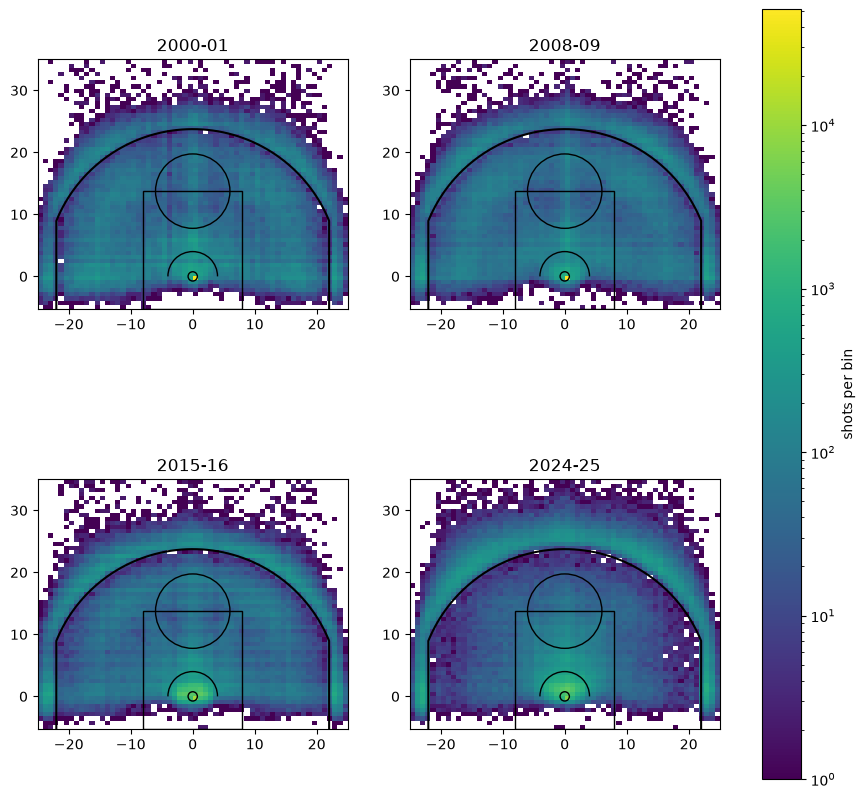

max_count 51291 | largest count drawn 51291


In [6]:
max_count = 0
for shots in cleaned_shots.values():
    counts, _, _ = np.histogram2d(
        shots["x_ft"],
        shots["y_ft"],
        bins=60,
        range=[[-court.SIDELINE_X, court.SIDELINE_X], [court.BASELINE_Y, court.DRAWN_TOP_Y]],
    )
    max_count = max(max_count, counts.max())
max_count = int(max_count)

fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for ax, (season, shots) in zip(axes.flat, cleaned_shots.items(), strict=True):
    court.plot_shot_heatmap(shots["x_ft"], shots["y_ft"], ax=ax, bins=60, max_count=max_count)
    ax.set_title(season)
fig.colorbar(axes.flat[0].collections[0], ax=axes, label="shots per bin")
plt.show()

drawn_max = 0
for ax in axes.flat:
    drawn_max = max(drawn_max, ax.collections[0].get_array().max())
print("max_count", max_count, "| largest count drawn", int(drawn_max))

**Interpretation**

Each square on these courts is colored by how many shots were taken there, with brighter meaning more shots. In 2000-01 and 2008-09 the color is spread fairly evenly inside the arc, plus one very bright dot at the rim. By 2024-25 the inside of the arc goes dark and the brightest areas are at the basket and in a band just outside the 3-point line. That dark strip just inside the line is what the network needs to notice to find the line on its own.

### Shot distance

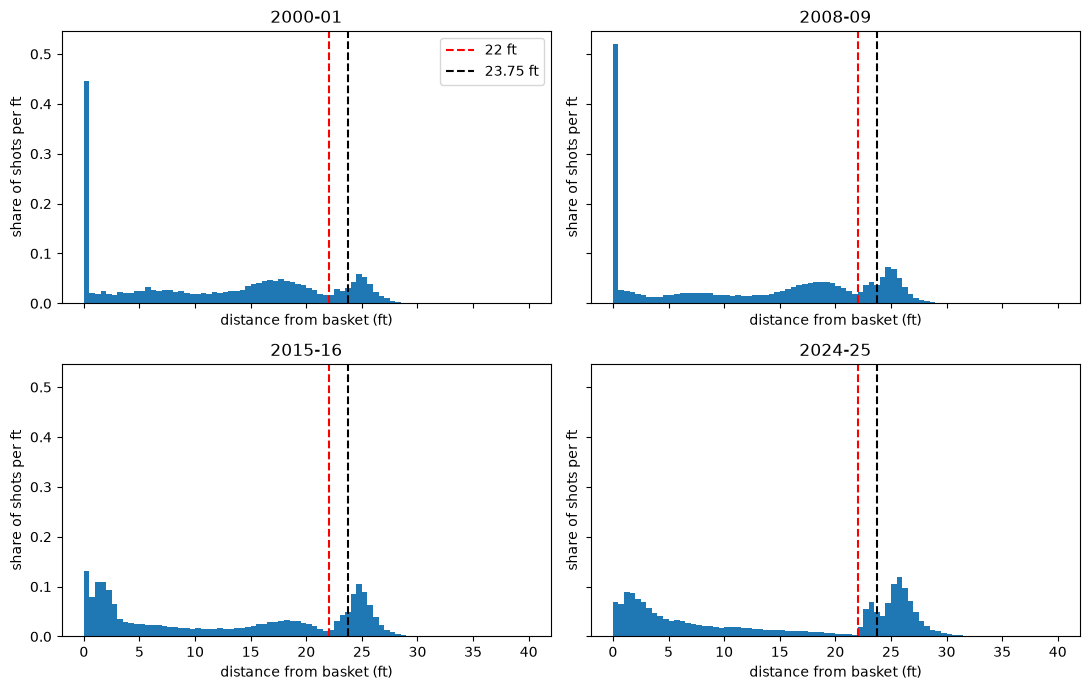

In [7]:
bins = np.arange(0, 40.5, 0.5)
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey=True)
for ax, (season, shots) in zip(axes.flat, cleaned_shots.items(), strict=True):
    ax.hist(shots["distance_ft"], bins=bins, density=True)
    ax.axvline(court.CORNER_THREE_X, color="red", linestyle="--", label="22 ft")
    ax.axvline(court.ARC_RADIUS, color="black", linestyle="--", label="23.75 ft")
    ax.set_title(season)
    ax.set_xlabel("distance from basket (ft)")
    ax.set_ylabel("share of shots per ft")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

In [8]:
for season, shots in cleaned_shots.items():
    at_center = (shots["LOC_X"] == 0) & (shots["LOC_Y"] == 0)
    print(f"{season}: {at_center.mean():.1%} of shots recorded at exactly (0, 0)")

2000-01: 21.6% of shots recorded at exactly (0, 0)
2008-09: 25.2% of shots recorded at exactly (0, 0)
2015-16: 0.0% of shots recorded at exactly (0, 0)
2024-25: 2.6% of shots recorded at exactly (0, 0)


**Interpretation**

These bars show how far from the basket shots were taken in each season. The tall spike at 0 ft in the two older seasons is about a quarter of their shots being logged at the exact center of the basket, which is a recording habit and not real shooting positions. The bump around 15 to 20 ft is mid-range shots, and it flattens out over the years. In 2024-25 almost nothing comes from just inside 22 ft, a small bump between the two dashed lines comes from corner threes, and the main peak sits around 25 ft, just behind the line. In one picture, players moved from the mid-range to just behind the line.

### Shot share by zone

                       2000-01  2008-09  2015-16  2024-25
SHOT_ZONE_BASIC                                          
Restricted Area          0.294    0.328    0.325    0.279
In The Paint (Non-RA)    0.157    0.128    0.146    0.203
Mid-Range                0.380    0.322    0.246    0.098
Left Corner 3            0.021    0.034    0.038    0.056
Right Corner 3           0.021    0.030    0.035    0.052
Above the Break 3        0.126    0.158    0.209    0.312


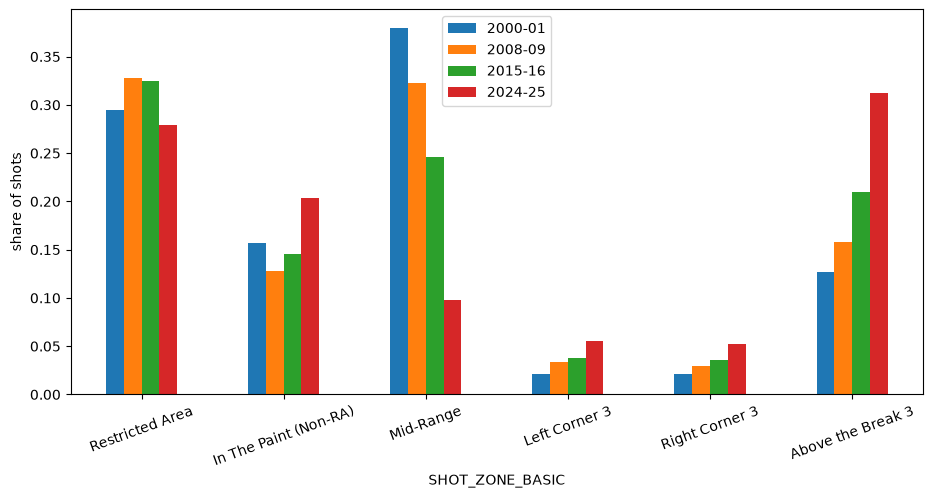

In [9]:
zone_share = pd.DataFrame()
for season, shots in cleaned_shots.items():
    zone_share[season] = shots["SHOT_ZONE_BASIC"].value_counts(normalize=True)
zone_share = zone_share.reindex(data.ZONES)
print(zone_share.round(3))
zone_share.plot.bar(figsize=(11, 5), ylabel="share of shots", rot=20)
plt.show()

**Interpretation**

Each bar is the share of a season's shots taken from one of the NBA's official zones. Mid-range drops from 38% of shots in 2000-01 to under 10% in 2024-25, while threes from above the top of the arc rise from 13% to 31%. Overall, threes go from 17% to 42% of all shots. The more shots gather behind the line, the easier the line should be for the network to find.

## 2. Experiments 1 and 2: Finding the line in 2000-01 and 2024-25

Both seasons use court coordinates in feet (cartesian inputs). Each network trains on the same 20,000 shots as section 1 and is scored on every shot from the held-out games. Every run uses 5 seeds, and seed 0 is the representative seed for the per-cell tables and single-seed plots.

The k-means and random rows are the baselines. The majority row is the accuracy of always guessing the more common shot type in the training set.

In [10]:
from threept import experiments, metrics, network

SEEDS = (0, 1, 2, 3, 4)
SEASONS_12 = ["2000-01", "2024-25"]
N_CELLS = 6
SUMMARY_COLUMNS = ["accuracy", "qe", "ari", "dead_cells", "mean_arc_purity"]

In [11]:
season_results = {}
season_weights = {}
baseline_results = {}
for season in SEASONS_12:
    train, test = splits[season]
    key = (season, N_CELLS)
    season_results[key], season_weights[key] = experiments.run_season(
        train, test, kind="cartesian", n_cells=N_CELLS, seeds=SEEDS
    )
    baseline_results[key] = experiments.run_baselines(
        train, test, kind="cartesian", n_cells=N_CELLS, seeds=SEEDS
    )
    assert len(season_results[key]) == len(SEEDS)
    assert len(baseline_results[key]) == 2 * len(SEEDS)
    print(season, "K =", N_CELLS)
    print(season_results[key].round(3).to_string(index=False))
    print()

2000-01 K = 6
 seed  accuracy  baseline    qe   ari   rim  mid_range  beyond_20  mean_arc_purity  dead_cells  kmeans_gap
    0      0.83      0.83 4.315 0.389 0.430      0.266      0.304            0.406           0       0.355
    1      0.83      0.83 4.310 0.387 0.427      0.262      0.310            0.399           0       0.305
    2      0.83      0.83 4.329 0.383 0.431      0.260      0.309            0.399           0       0.233
    3      0.83      0.83 4.332 0.388 0.430      0.264      0.306            0.402           0       0.310
    4      0.83      0.83 4.288 0.386 0.429      0.260      0.311            0.396           0       0.309



2024-25 K = 6
 seed  accuracy  baseline    qe   ari   rim  mid_range  beyond_20  mean_arc_purity  dead_cells  kmeans_gap
    0     0.943     0.583 4.425 0.522 0.402      0.124      0.474            0.868           0       4.179
    1     0.944     0.583 4.440 0.518 0.405      0.122      0.473            0.870           0       4.196
    2     0.944     0.583 4.457 0.514 0.411      0.116      0.472            0.870           0       4.057
    3     0.944     0.583 4.474 0.511 0.410      0.118      0.472            0.871           0       4.368
    4     0.944     0.583 4.447 0.519 0.405      0.122      0.473            0.869           0       4.196



In [12]:
summary_tables = {}
for season in SEASONS_12:
    key = (season, N_CELLS)
    baselines = baseline_results[key]
    network_summary = experiments.summarize(season_results[key])
    kmeans_summary = experiments.summarize(baselines[baselines["method"] == "kmeans"])
    random_summary = experiments.summarize(baselines[baselines["method"] == "random"])
    summary_tables[season] = pd.concat(
        {
            "network": network_summary.loc[SUMMARY_COLUMNS],
            "kmeans": kmeans_summary.loc[SUMMARY_COLUMNS],
            "random": random_summary.loc[SUMMARY_COLUMNS],
            "majority": network_summary.loc[["baseline"]],
        }
    )
    gap = network_summary.loc["kmeans_gap"]
    print(f"{season} K = {N_CELLS}: mean k-means gap {gap['mean']:.2f} ft (std {gap['std']:.2f})")
summary_table = pd.concat(summary_tables, axis=1)
summary_table.round(3)

2000-01 K = 6: mean k-means gap 0.30 ft (std 0.04)
2024-25 K = 6: mean k-means gap 4.20 ft (std 0.11)


2000-01        2024-25       
                            mean    std    mean    std
network  accuracy          0.830  0.000   0.944  0.001
         qe                4.315  0.018   4.449  0.018
         ari               0.387  0.002   0.517  0.004
         dead_cells        0.000  0.000   0.000  0.000
         mean_arc_purity   0.400  0.004   0.870  0.001
kmeans   accuracy          0.830  0.000   0.917  0.000
         qe                4.305  0.000   4.464  0.000
         ari               0.387  0.000   0.441  0.000
         dead_cells        0.000  0.000   0.000  0.000
         mean_arc_purity   0.399  0.000   0.830  0.000
random   accuracy          0.847  0.017   0.894  0.025
         qe                6.253  0.823   6.711  0.662
         ari               0.338  0.060   0.424  0.040
         dead_cells        0.800  0.447   0.000  0.000
         mean_arc_purity   0.520  0.147   0.906  0.027
majority baseline          0.830  0.000   0.583  0.000

In [13]:
allocation_tables = {}
for season in SEASONS_12:
    per_seed = []
    for weights in season_weights[(season, N_CELLS)]:
        distances = metrics.prototype_distances(weights, "cartesian")
        per_seed.append(metrics.cell_allocation(distances))
    per_seed = pd.DataFrame(per_seed)
    assert (per_seed.sum(axis=1) == N_CELLS).all()
    allocation_tables[season] = pd.DataFrame({"mean": per_seed.mean(), "seed 0": per_seed.iloc[0]})
allocation_table = pd.concat(allocation_tables, axis=1)
allocation_table.round(2)

2000-01        2024-25       
             mean seed 0    mean seed 0
rim           1.0      1     1.0      1
mid_range     2.0      2     1.0      1
beyond_20     3.0      3     4.0      4

**Interpretation**

The network splits the court into cells, and each cell moves to the center of the shots it collects. I call a cell a "3" cell if most of its shots are threes, then check those labels on games it never trained on. In 2024-25 those labels are right 94% of the time, compared with 58% for just guessing "2" every time, and the cells beyond 20 ft collect shots that are 87% threes. In 2000-01 the network does no better than guessing "2" (83%), because threes were too rare to form their own group. So the network finds where players like to shoot, and that only matches the line once players start shooting from just behind it.

### K sweep

In [14]:
for n_cells in (12, 20):
    for season in SEASONS_12:
        train, test = splits[season]
        key = (season, n_cells)
        season_results[key], season_weights[key] = experiments.run_season(
            train, test, kind="cartesian", n_cells=n_cells, seeds=SEEDS
        )
        baseline_results[key] = experiments.run_baselines(
            train, test, kind="cartesian", n_cells=n_cells, seeds=SEEDS
        )
        assert len(season_results[key]) == len(SEEDS)
        assert len(baseline_results[key]) == 2 * len(SEEDS)

In [15]:
for n_cells in (12, 20):
    sweep_tables = {}
    for season in SEASONS_12:
        baselines = baseline_results[(season, n_cells)]
        network_summary = experiments.summarize(season_results[(season, n_cells)])
        kmeans_summary = experiments.summarize(baselines[baselines["method"] == "kmeans"])
        random_summary = experiments.summarize(baselines[baselines["method"] == "random"])
        sweep_tables[season] = pd.concat(
            {
                "network": network_summary.loc[SUMMARY_COLUMNS],
                "kmeans": kmeans_summary.loc[SUMMARY_COLUMNS],
                "random": random_summary.loc[SUMMARY_COLUMNS],
                "majority": network_summary.loc[["baseline"]],
            }
        )
    sweep_table = pd.concat(sweep_tables, axis=1)
    print(f"Summary at K = {n_cells}")
    print(sweep_table.round(3).to_string())
    print()

Summary at K = 12
                         2000-01        2024-25       
                            mean    std    mean    std
network  accuracy          0.853  0.008   0.980  0.003
         qe                3.007  0.046   3.049  0.083
         ari               0.459  0.004   0.554  0.056
         dead_cells        0.000  0.000   0.000  0.000
         mean_arc_purity   0.511  0.029   0.952  0.005
kmeans   accuracy          0.860  0.003   0.971  0.001
         qe                2.966  0.003   2.870  0.009
         ari               0.455  0.003   0.528  0.021
         dead_cells        0.000  0.000   0.000  0.000
         mean_arc_purity   0.507  0.015   0.934  0.002
random   accuracy          0.869  0.026   0.931  0.032
         qe                4.715  0.519   5.021  1.011
         ari               0.389  0.043   0.361  0.095
         dead_cells        2.200  1.924   0.000  0.000
         mean_arc_purity   0.620  0.086   0.937  0.015
majority baseline          0.830  0.000   0.583

In [16]:
for n_cells in (12, 20):
    sweep_allocation = {}
    for season in SEASONS_12:
        per_seed = []
        for weights in season_weights[(season, n_cells)]:
            distances = metrics.prototype_distances(weights, "cartesian")
            per_seed.append(metrics.cell_allocation(distances))
        per_seed = pd.DataFrame(per_seed)
        assert (per_seed.sum(axis=1) == n_cells).all()
        sweep_allocation[season] = pd.DataFrame(
            {"mean": per_seed.mean(), "seed 0": per_seed.iloc[0]}
        )
    print(f"Prototypes under 8 ft, 8 to 20 ft and beyond 20 ft at K = {n_cells}")
    print(pd.concat(sweep_allocation, axis=1).round(2).to_string())
    print()

Prototypes under 8 ft, 8 to 20 ft and beyond 20 ft at K = 12
          2000-01        2024-25       
             mean seed 0    mean seed 0
rim           2.4      3     3.0      2
mid_range     4.6      3     3.6      4
beyond_20     5.0      6     5.4      6

Prototypes under 8 ft, 8 to 20 ft and beyond 20 ft at K = 20
          2000-01        2024-25       
             mean seed 0    mean seed 0
rim           3.8      4     4.6      5
mid_range     8.8      8     6.0      7
beyond_20     7.4      8     9.4      8



### Seed 0, K = 6

In [17]:
test_labels_k6 = {}
for season in SEASONS_12:
    train, test = splits[season]
    weights = season_weights[(season, N_CELLS)][0]
    train_inputs = data.get_inputs(train, "cartesian")
    test_inputs = data.get_inputs(test, "cartesian")
    train_labels = network.assign(train_inputs, weights)
    test_labels_k6[season] = network.assign(test_inputs, weights)
    cell_table = pd.DataFrame(
        {
            "distance (ft)": metrics.prototype_distances(weights, "cartesian"),
            "angle (deg)": np.degrees(metrics.prototype_angles(weights, "cartesian")),
            "3PT share (test)": metrics.three_point_purity(
                test_labels_k6[season], test["is_three"].to_numpy(), N_CELLS
            ),
            "wins (train)": network.count_wins(train_inputs, weights),
        }
    )
    cell_table.index.name = "cell"
    assert cell_table["wins (train)"].sum() == len(train)
    dead_cells = season_results[(season, N_CELLS)].loc[0, "dead_cells"]
    assert (cell_table["wins (train)"] == 0).sum() == dead_cells
    print(f"{season}, seed 0, K = {N_CELLS}")
    print(cell_table.round(3).to_string())
    print()

2000-01, seed 0, K = 6
      distance (ft)  angle (deg)  3PT share (test)  wins (train)
cell                                                            
0            21.297      -40.691             0.435          2155
1            21.601       39.830             0.429          2252
2             1.671        0.449             0.000          8604
3            16.234       81.000             0.179          2468
4            21.021       -0.715             0.353          1643
5            16.066      -80.589             0.160          2878

2024-25, seed 0, K = 6
      distance (ft)  angle (deg)  3PT share (test)  wins (train)
cell                                                            
0             1.815        4.315             0.000          7888
1            21.937      -80.688             0.822          1654
2            10.229       -0.120             0.000          2491
3            21.628       74.099             0.819          1815
4            25.105      -30.541           

In [18]:
for season in SEASONS_12:
    train, test = splits[season]
    confusion = metrics.zone_confusion(
        test_labels_k6[season], test["SHOT_ZONE_BASIC"].to_numpy(), data.ZONES, N_CELLS
    )
    assert confusion.to_numpy().sum() == len(test)
    print(f"{season}, seed 0, K = {N_CELLS}: test shots by cell (rows) and official zone (columns)")
    print(confusion.to_string())
    print()

2000-01, seed 0, K = 6: test shots by cell (rows) and official zone (columns)
zone  Restricted Area  In The Paint (Non-RA)  Mid-Range  Left Corner 3  Right Corner 3  Above the Break 3
cell                                                                                                     
0                   0                    178       2205              0               0               1831
1                   0                    216       2275              0               0               1867
2               11166                   5310          8              0               0                  0
3                   0                     11       3817              0             788                 48
4                   0                    310       1673              0               0               1075
5                   0                     39       4594            855               0                 26

2024-25, seed 0, K = 6: test shots by cell (rows) and official zone (colu

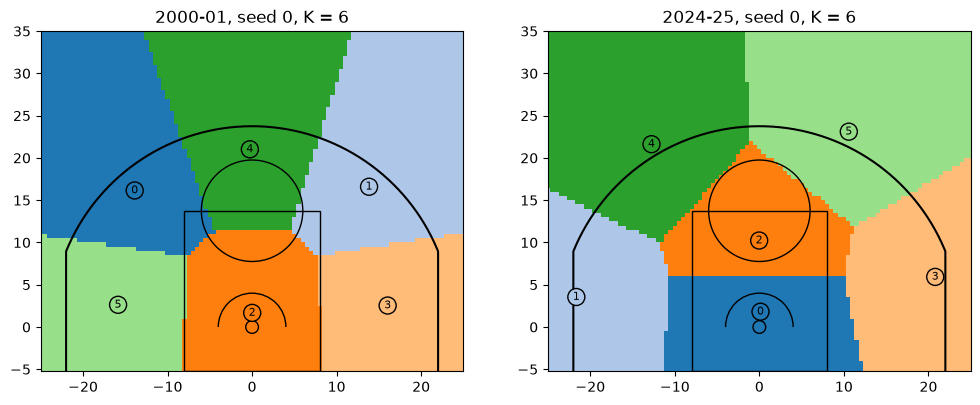

In [19]:
grid_x, grid_y = court.court_grid()
grid_points = np.column_stack([grid_x.ravel(), grid_y.ravel()])
grid_inputs = data.court_to_inputs(grid_points, "cartesian")
fig, axes = plt.subplots(1, 2, figsize=(12, 7))
for ax, season in zip(axes, SEASONS_12, strict=True):
    weights = season_weights[(season, N_CELLS)][0]
    grid_labels = network.assign(grid_inputs, weights).reshape(grid_x.shape)
    court.plot_zone_map(grid_x, grid_y, grid_labels, ax=ax)
    court.plot_prototypes(weights, ax=ax)
    ax.set_title(f"{season}, seed 0, K = {N_CELLS}")
plt.show()

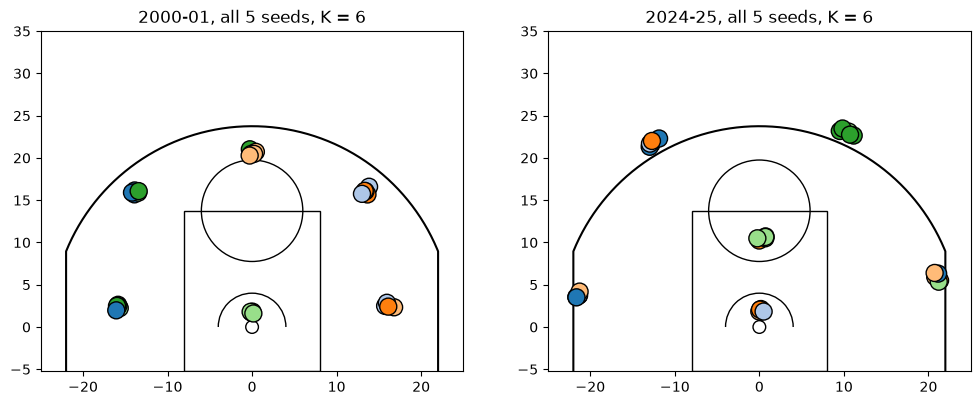

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 7))
for ax, season in zip(axes, SEASONS_12, strict=True):
    court.draw_half_court(ax=ax)
    for weights in season_weights[(season, N_CELLS)]:
        court.plot_prototypes(weights, ax=ax, numbered=False)
    ax.set_title(f"{season}, all {len(SEEDS)} seeds, K = {N_CELLS}")
plt.show()

**Interpretation**

In the court plots, each color is the area one cell owns, and each dot is that cell's center. With 6 cells in 2024-25, one cell covers the rim and most of the rest sit just outside the arc. More cells make the line sharper. With 12 cells, 2024-25 accuracy reaches 98% and the outer cells are 95% threes, and 2000-01 finally beats guessing "2" with 20 cells (95%). The network also beat k-means, a common method that groups all shots at once (94% against 92%). Cells dropped at random shots with no learning still scored fairly well, because so many shots are of one type, but they sat much farther from their shots (6.7 ft against 4.4 ft) and changed a lot between runs.

## 3. Experiment 3: Sequential training across eras

One network trains through the four seasons in time order, with the weights carried from each season to the next and the learning rate reset every season. It uses court coordinates, K = 6 and the same 5 seeds as section 2. Seed 0 is the representative seed for single-seed tables and plots.

In [21]:
seasons = []
for name in data.SEASONS:
    train, test = splits[name]
    seasons.append((name, train, test))

sequential_weights = {}
sequential_tables = []
for seed in SEEDS:
    sequential_weights[seed], table = experiments.run_sequential(
        seasons, kind="cartesian", n_cells=N_CELLS, seed=seed
    )
    table["seed"] = seed
    sequential_tables.append(table)
    assert len(sequential_weights[seed]) == len(seasons)
    for weights in sequential_weights[seed]:
        assert weights.shape == (N_CELLS, 2)
    first_season_weights = season_weights[("2000-01", N_CELLS)][seed]
    assert np.array_equal(sequential_weights[seed][0], first_season_weights)
sequential_results = pd.concat(sequential_tables, ignore_index=True)

first_rows = sequential_results["season"] == "2000-01"
shares = sequential_results[["rim", "mid_range", "beyond_20"]].sum(axis=1)
assert len(sequential_results) == len(SEEDS) * len(seasons)
assert sequential_results.loc[first_rows, "mean_movement"].isna().all()
assert sequential_results.loc[~first_rows, "mean_movement"].notna().all()
assert np.allclose(shares, 1)

### Per-season table

In [22]:
majority_by_season = {}
for name, train, test in seasons:
    majority_by_season[name] = metrics.majority_baseline_accuracy(
        train["is_three"], test["is_three"]
    )
sequential_results["majority"] = sequential_results["season"].map(majority_by_season)

table_columns = ["mean_movement", "rim", "mid_range", "beyond_20", "accuracy", "majority"]
seed_zero = sequential_results[sequential_results["seed"] == 0]
print("Seed 0")
seed_zero_table = seed_zero.set_index("season")[table_columns]
print(seed_zero_table.round(3).to_string())
print()
print(f"Mean across {len(SEEDS)} seeds")
mean_table = sequential_results.groupby("season", sort=False)[table_columns].mean()
print(mean_table.round(3).to_string())

Seed 0
         mean_movement    rim  mid_range  beyond_20  accuracy  majority
season                                                                 
2000-01            NaN  0.430      0.266      0.304     0.830     0.830
2008-09          0.996  0.446      0.219      0.335     0.773     0.773
2015-16          0.814  0.466      0.186      0.349     0.769     0.714
2024-25          2.593  0.499      0.000      0.501     0.916     0.583

Mean across 5 seeds
         mean_movement    rim  mid_range  beyond_20  accuracy  majority
season                                                                 
2000-01            NaN  0.430      0.263      0.308     0.830     0.830
2008-09          1.158  0.446      0.219      0.335     0.773     0.773
2015-16          0.837  0.466      0.182      0.352     0.766     0.714
2024-25          2.695  0.500      0.000      0.500     0.917     0.583


### Cell allocation by season

In [23]:
allocation_rows = []
for seed in SEEDS:
    for name, weights in zip(data.SEASONS, sequential_weights[seed], strict=True):
        distances = metrics.prototype_distances(weights, "cartesian")
        row = metrics.cell_allocation(distances)
        assert row["rim"] + row["mid_range"] + row["beyond_20"] == N_CELLS
        row["season"] = name
        row["seed"] = seed
        allocation_rows.append(row)
allocation = pd.DataFrame(allocation_rows)

allocation_columns = ["rim", "mid_range", "beyond_20"]
seed_zero_allocation = allocation[allocation["seed"] == 0].set_index("season")
mean_allocation = allocation.groupby("season", sort=False)[allocation_columns].mean()
print("Prototypes under 8 ft, 8 to 20 ft and beyond 20 ft")
pd.concat(
    {"mean": mean_allocation, "seed 0": seed_zero_allocation[allocation_columns]}, axis=1
).round(2)

Prototypes under 8 ft, 8 to 20 ft and beyond 20 ft


mean                     seed 0                    
         rim mid_range beyond_20    rim mid_range beyond_20
season                                                     
2000-01  1.0       2.0       3.0      1         2         3
2008-09  1.0       2.0       3.0      1         2         3
2015-16  1.0       2.0       3.0      1         2         3
2024-25  1.0       0.0       5.0      1         0         5

### Prototype paths, seed 0

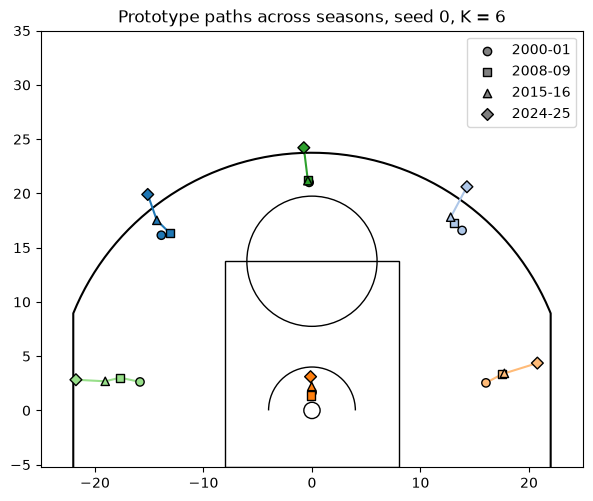

In [24]:
fig, ax = plt.subplots(figsize=(7, 8))
court.draw_half_court(ax=ax)
court.plot_prototype_paths(sequential_weights[0], list(data.SEASONS), ax=ax)
ax.set_title(f"Prototype paths across seasons, seed 0, K = {N_CELLS}")
plt.show()

### Arc and mid-range shares by season

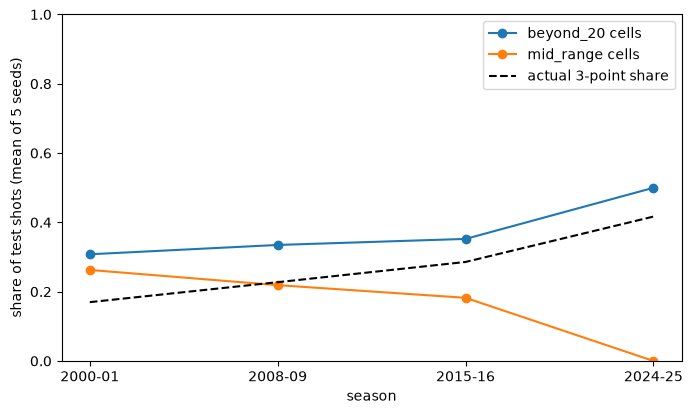

In [25]:
three_point_share = []
for name in data.SEASONS:
    three_point_share.append(splits[name][1]["is_three"].mean())

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(mean_table.index, mean_table["beyond_20"], marker="o", label="beyond_20 cells")
ax.plot(mean_table.index, mean_table["mid_range"], marker="o", label="mid_range cells")
ax.plot(
    mean_table.index,
    three_point_share,
    linestyle="--",
    color="black",
    label="actual 3-point share",
)
ax.set_xlabel("season")
ax.set_ylabel(f"share of test shots (mean of {len(SEEDS)} seeds)")
ax.set_ylim(0, 1)
ax.legend()
plt.show()

### Final sequential map against a fresh 2024-25 network

In [26]:
gap_rows = []
for seed in SEEDS:
    final_weights = sequential_weights[seed][-1]
    fresh_weights = season_weights[("2024-25", N_CELLS)][seed]
    gap = metrics.prototype_gap(final_weights, fresh_weights)
    assert gap >= 0
    gap_rows.append({"seed": seed, "gap (ft)": gap})
gap_table = pd.DataFrame(gap_rows).set_index("seed")
print(gap_table.round(2).to_string())
print(f"mean gap {gap_table['gap (ft)'].mean():.2f} ft")

      gap (ft)
seed          
0         4.17
1         4.33
2         4.09
3         4.44
4         3.98
mean gap 4.20 ft


**Interpretation**

Here one network learns the four seasons in order, carrying its cells forward from one season to the next. The table shows where its cells end up each season, and the path plot shows each cell's center moving from season to season. Three of its six cells sit beyond 20 ft until 2015-16, then in 2024-25 the last mid-range cell moves out to the arc, leaving five. In the line chart, the share of shots won by those outer cells rises from 31% to 50%, alongside the dashed line for the real share of threes. Its accuracy ties guessing "2" in 2008-09, pulls ahead in 2015-16, and leads clearly by 2024-25 (92% against 58%). The network's map shifted the same way the league did.

## 4. Experiment 4: Polar inputs and the shape of the line

Polar inputs describe each shot by its distance from the basket and its position along the arc: `[distance_ft, 23.75 * angle]`. The angle is clipped to ±(pi/2 + 0.25) so shots right behind the rim do not wrap around. K-means uses the same inputs. Everything else matches section 2: the same 20,000 training shots, the same held-out test games, K = 6, 12 and 20, and 5 seeds. Seed 0 is the representative seed.

The shape test looks only at cells beyond 20 ft. A corner cell has an angle of 1.2 rad or more from straight-on. A top cell has an angle of 0.4 rad or less. The line is 22 ft from the basket in the corners and 23.75 ft at the top, so corner cells are expected to sit closer to the basket. A mean shows NaN when that group was empty.

In [27]:
K_VALUES = (6, 12, 20)
cartesian_keys = set(season_results)
polar_results = {}
polar_weights = {}
polar_baselines = {}
for n_cells in K_VALUES:
    for season in SEASONS_12:
        train, test = splits[season]
        key = (season, n_cells)
        polar_results[key], polar_weights[key] = experiments.run_season(
            train, test, kind="polar", n_cells=n_cells, seeds=SEEDS
        )
        polar_baselines[key] = experiments.run_baselines(
            train, test, kind="polar", n_cells=n_cells, seeds=SEEDS
        )
        assert len(polar_results[key]) == len(SEEDS)
        assert len(polar_baselines[key]) == 2 * len(SEEDS)
        for weights in polar_weights[key]:
            assert weights.shape == (n_cells, 2)
assert set(polar_results) == cartesian_keys
weights_by_kind = {"polar": polar_weights, "cartesian": season_weights}

### Summary against the baselines

In [28]:
results_by_kind = {"polar": polar_results, "cartesian": season_results}
baselines_by_kind = {"polar": polar_baselines, "cartesian": baseline_results}
for n_cells in K_VALUES:
    polar_tables = {}
    for season in SEASONS_12:
        key = (season, n_cells)
        by_kind = {}
        for kind in ("polar", "cartesian"):
            runs = baselines_by_kind[kind][key]
            network_summary = experiments.summarize(results_by_kind[kind][key])
            kmeans_summary = experiments.summarize(runs[runs["method"] == "kmeans"])
            random_summary = experiments.summarize(runs[runs["method"] == "random"])
            by_kind[kind] = pd.concat(
                {
                    "network": network_summary.loc[SUMMARY_COLUMNS],
                    "kmeans": kmeans_summary.loc[SUMMARY_COLUMNS],
                    "random": random_summary.loc[SUMMARY_COLUMNS],
                    "majority": network_summary.loc[["baseline"]],
                }
            )
        polar_majority = by_kind["polar"].loc[("majority", "baseline"), "mean"]
        cartesian_majority = by_kind["cartesian"].loc[("majority", "baseline"), "mean"]
        assert polar_majority == cartesian_majority
        polar_tables[season] = pd.concat(by_kind, axis=1)
        gap = experiments.summarize(polar_results[key]).loc["kmeans_gap"]
        gap_mean, gap_std = gap["mean"], gap["std"]
        print(f"{season} K = {n_cells}: polar k-means gap {gap_mean:.2f} ft (std {gap_std:.2f})")
    print(f"Summary at K = {n_cells}, mean and std over {len(SEEDS)} seeds")
    print(pd.concat(polar_tables, axis=1).round(3).to_string())
    print()

2000-01 K = 6: polar k-means gap 0.50 ft (std 0.11)
2024-25 K = 6: polar k-means gap 8.42 ft (std 6.74)
Summary at K = 6, mean and std over 5 seeds
                         2000-01                         2024-25                        
                           polar        cartesian          polar        cartesian       
                            mean    std      mean    std    mean    std      mean    std
network  accuracy          0.830  0.000     0.830  0.000   0.926  0.027     0.944  0.001
         qe                6.017  0.021     4.315  0.018   7.730  0.027     4.449  0.018
         ari               0.289  0.001     0.387  0.002   0.312  0.005     0.517  0.004
         dead_cells        0.000  0.000     0.000  0.000   0.000  0.000     0.000  0.000
         mean_arc_purity   0.407  0.005     0.400  0.004   0.862  0.010     0.870  0.001
kmeans   accuracy          0.830  0.000     0.830  0.000   0.879  0.003     0.917  0.000
         qe                6.003  0.003     4.305  

### Cell allocation, polar

In [29]:
for n_cells in K_VALUES:
    polar_allocation = {}
    for season in SEASONS_12:
        per_seed = []
        for weights in polar_weights[(season, n_cells)]:
            distances = metrics.prototype_distances(weights, "polar")
            per_seed.append(metrics.cell_allocation(distances))
        per_seed = pd.DataFrame(per_seed)
        assert (per_seed.sum(axis=1) == n_cells).all()
        polar_allocation[season] = pd.DataFrame(
            {"mean": per_seed.mean(), "seed 0": per_seed.iloc[0]}
        )
    print(f"Polar prototypes under 8 ft, 8 to 20 ft and beyond 20 ft at K = {n_cells}")
    print(pd.concat(polar_allocation, axis=1).round(2).to_string())
    print()

Polar prototypes under 8 ft, 8 to 20 ft and beyond 20 ft at K = 6
          2000-01        2024-25       
             mean seed 0    mean seed 0
rim           1.0      1     2.8      3
mid_range     4.0      4     0.2      0
beyond_20     1.0      1     3.0      3

Polar prototypes under 8 ft, 8 to 20 ft and beyond 20 ft at K = 12
          2000-01        2024-25       
             mean seed 0    mean seed 0
rim           5.2      5     6.0      6
mid_range     4.0      4     1.0      1
beyond_20     2.8      3     5.0      5

Polar prototypes under 8 ft, 8 to 20 ft and beyond 20 ft at K = 20
          2000-01        2024-25       
             mean seed 0    mean seed 0
rim           8.6      9     8.6      9
mid_range     6.6      6     2.8      3
beyond_20     4.8      5     8.6      8



### Shape test

Each row is one input kind at one K. The first table shows distances and group sizes, averaged over seeds. A mean over seeds skips seeds where the group was empty, and shows NaN when every seed was empty. "corner_minus_top_ft" uses only seeds where both groups exist. The second table counts seeds.

In [30]:
shape_rows = []
for n_cells in K_VALUES:
    for season in SEASONS_12:
        for kind in ("polar", "cartesian"):
            for seed, weights in zip(SEEDS, weights_by_kind[kind][(season, n_cells)], strict=True):
                row = experiments.shape_test(weights, kind)
                arc_cells = (metrics.prototype_distances(weights, kind) > metrics.MID_MAX_FT).sum()
                assert row["n_corner"] + row["n_top"] <= arc_cells
                assert np.isnan(row["corner_mean_ft"]) == (row["n_corner"] == 0)
                assert np.isnan(row["top_mean_ft"]) == (row["n_top"] == 0)
                row.update(season=season, K=n_cells, input=kind, seed=seed)
                shape_rows.append(row)
shape_runs = pd.DataFrame(shape_rows)
shape_runs["corner_minus_top_ft"] = shape_runs["corner_mean_ft"] - shape_runs["top_mean_ft"]
shape_runs["has_corner"] = shape_runs["n_corner"] > 0
shape_runs["has_top"] = shape_runs["n_top"] > 0
shape_runs["has_both"] = shape_runs["corner_minus_top_ft"].notna()
shape_runs["corner_closer"] = shape_runs["corner_minus_top_ft"] < 0
assert len(shape_runs) == len(K_VALUES) * len(SEASONS_12) * 2 * len(SEEDS)

shape_groups = shape_runs.groupby(["K", "input", "season"])
shape_distances = shape_groups[
    ["corner_mean_ft", "top_mean_ft", "corner_minus_top_ft", "n_corner", "n_top"]
].mean()
shape_counts = shape_groups[["has_corner", "has_top", "has_both", "corner_closer"]].sum()
shape_counts.columns = ["seeds with corner", "seeds with top", "seeds with both", "corner < top"]
print(f"Shape test, mean over {len(SEEDS)} seeds")
print(shape_distances.unstack("season").round(2).to_string())
print()
print(f"Shape test, number of seeds out of {len(SEEDS)}")
print(shape_counts.unstack("season").to_string())

Shape test, mean over 5 seeds
             corner_mean_ft         top_mean_ft         corner_minus_top_ft         n_corner           n_top        
season              2000-01 2024-25     2000-01 2024-25             2000-01 2024-25  2000-01 2024-25 2000-01 2024-25
K  input                                                                                                            
6  cartesian            NaN   21.82       20.60   25.26                 NaN   -3.39      0.0     2.0     1.0     0.4
   polar                NaN   22.72       21.91   25.62                 NaN   -2.74      0.0     1.0     1.0     0.8
12 cartesian          21.32   22.95       22.21   26.14               -0.81   -3.18      0.8     2.0     1.0     1.0
   polar                NaN   22.82       22.25   26.35                 NaN   -3.53      0.0     2.0     0.8     1.0
20 cartesian          22.30   23.13       25.45   26.42               -3.14   -3.29      2.0     2.4     1.4     2.2
   polar              21.61   22.7

### Shape test, seed 0

In [31]:
shape_seed_zero = shape_runs[shape_runs["seed"] == 0].set_index(["K", "input", "season"])
shape_seed_zero = shape_seed_zero[
    ["corner_mean_ft", "top_mean_ft", "corner_minus_top_ft", "n_corner", "n_top"]
]
print(shape_seed_zero.unstack("season").round(2).to_string())

             corner_mean_ft         top_mean_ft         corner_minus_top_ft         n_corner           n_top        
season              2000-01 2024-25     2000-01 2024-25             2000-01 2024-25  2000-01 2024-25 2000-01 2024-25
K  input                                                                                                            
6  cartesian            NaN   21.78       21.02     NaN                 NaN     NaN        0       2       1       0
   polar                NaN   23.08       22.48   25.50                 NaN   -2.41        0       1       1       1
12 cartesian          21.49   22.86       22.77   26.14               -1.28   -3.29        2       2       1       1
   polar                NaN   22.79       22.72   26.39                 NaN   -3.60        0       2       1       1
20 cartesian          22.21   23.05       25.76   26.42               -3.55   -3.38        2       2       2       2
   polar              21.75   22.93       26.27   26.38         

### Does averaging along the arc pull a prototype inside it?

For each beyond-20 cell, this compares the prototype's distance from the basket with the mean distance of the training shots it wins. A negative gap means the prototype sits closer to the basket than its own shots. Beyond-20 cells that win no training shots are skipped.

In [32]:
arc_frames = []
for n_cells in K_VALUES:
    for season in SEASONS_12:
        train, _ = splits[season]
        for kind in ("polar", "cartesian"):
            train_inputs = data.get_inputs(train, kind)
            for weights in weights_by_kind[kind][(season, n_cells)]:
                labels = network.assign(train_inputs, weights)
                shot_distance = train["distance_ft"].groupby(labels).mean()
                prototype_distance = metrics.prototype_distances(weights, kind)
                cells = pd.DataFrame(
                    {
                        "prototype_ft": prototype_distance[shot_distance.index],
                        "shot_ft": shot_distance.to_numpy(),
                    }
                )
                arc_cells = cells[cells["prototype_ft"] > metrics.MID_MAX_FT].copy()
                arc_cells["gap_ft"] = arc_cells["prototype_ft"] - arc_cells["shot_ft"]
                arc_cells["K"] = n_cells
                arc_cells["season"] = season
                arc_cells["input"] = kind
                arc_frames.append(arc_cells)
arc_gap = pd.concat(arc_frames)
arc_groups = arc_gap.groupby(["K", "input", "season"])
arc_summary = arc_groups[["prototype_ft", "shot_ft", "gap_ft"]].mean()
arc_summary["arc cells"] = arc_groups.size()
print(f"Beyond-20 cells pooled over {len(SEEDS)} seeds")
print(arc_summary.unstack("season").round(2).to_string())

Beyond-20 cells pooled over 5 seeds
             prototype_ft         shot_ft          gap_ft         arc cells        
season            2000-01 2024-25 2000-01 2024-25 2000-01 2024-25   2000-01 2024-25
K  input                                                                           
6  cartesian        20.86   23.53   21.17   24.18   -0.31   -0.66        15      20
   polar            21.91   24.36   21.87   24.32    0.04    0.04         5      15
12 cartesian        22.19   24.85   22.40   25.17   -0.21   -0.32        25      27
   polar            22.18   24.69   22.12   24.65    0.05    0.04        14      25
20 cartesian        24.25   25.33   24.43   25.45   -0.18   -0.11        37      47
   polar            24.12   25.04   24.12   25.02   -0.00    0.02        24      43


### Zone maps and prototypes, seed 0

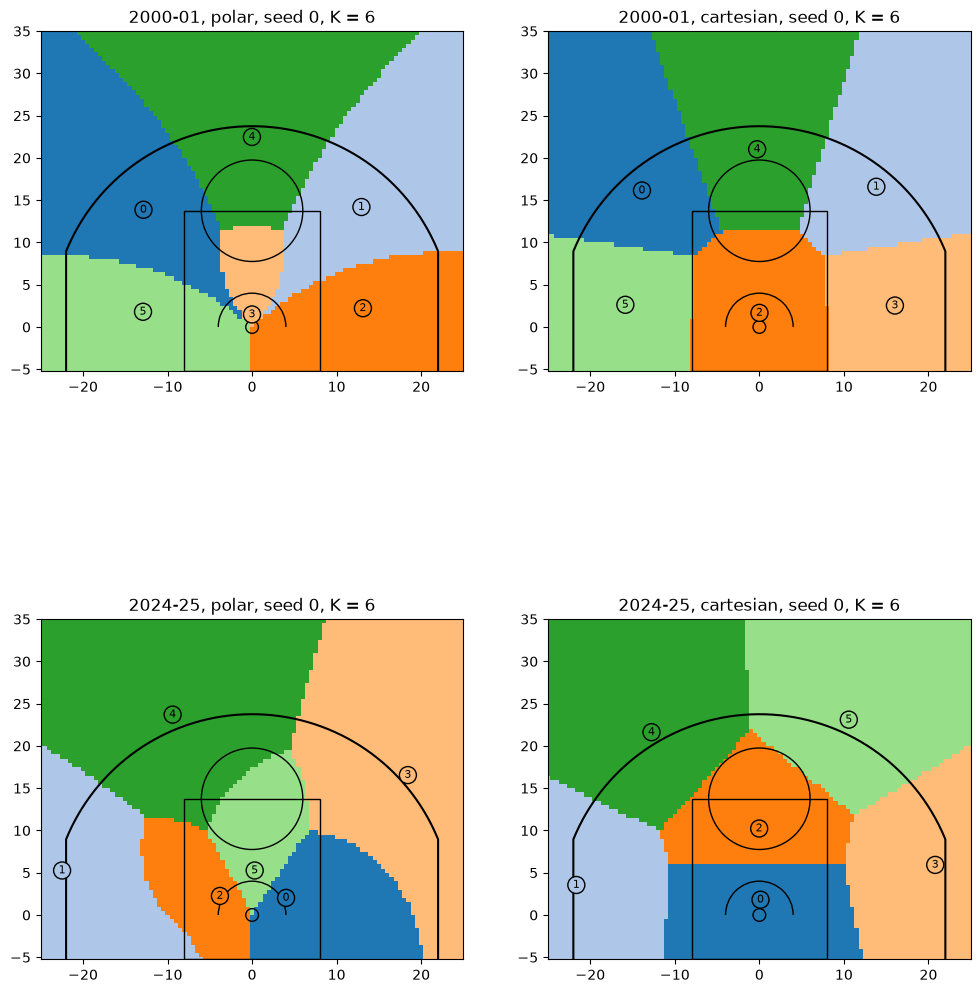

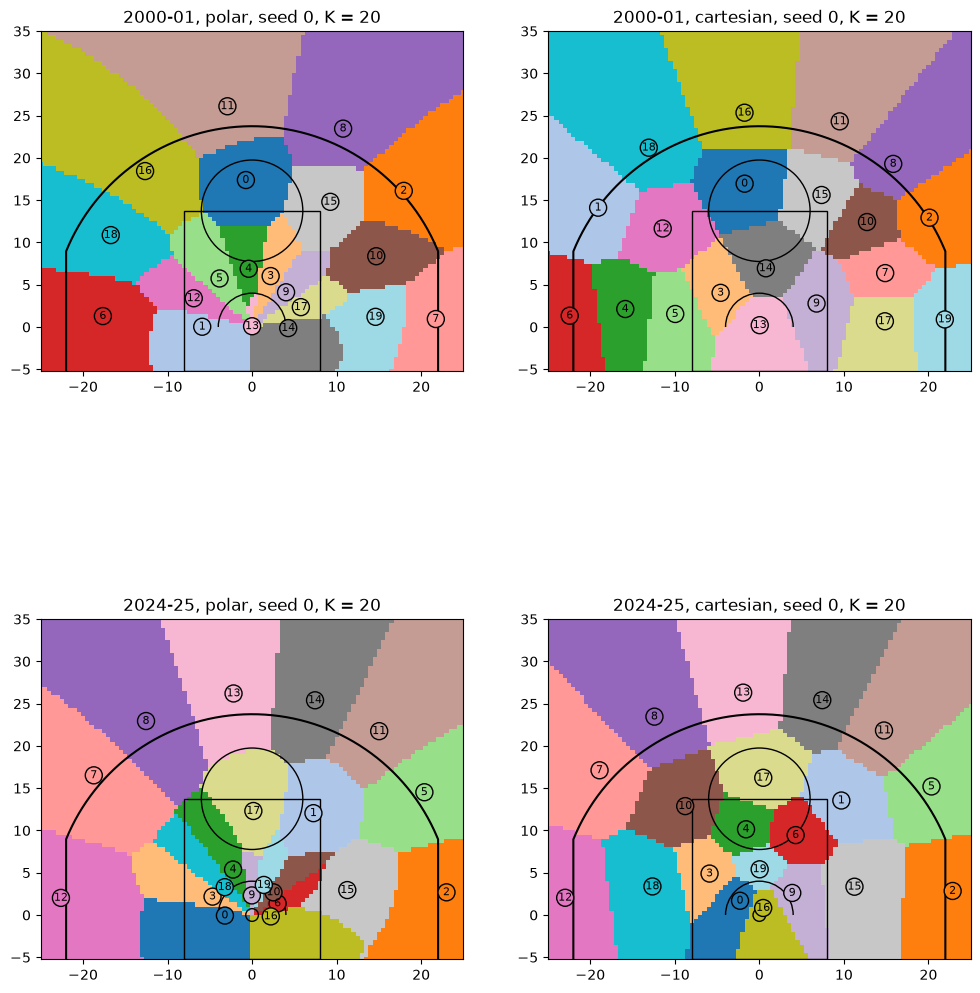

In [33]:
grid_x, grid_y = court.court_grid()
grid_points = np.column_stack([grid_x.ravel(), grid_y.ravel()])
for n_cells in (6, 20):
    fig, axes = plt.subplots(2, 2, figsize=(12, 14))
    for row, season in enumerate(SEASONS_12):
        for column, kind in enumerate(("polar", "cartesian")):
            ax = axes[row, column]
            weights = weights_by_kind[kind][(season, n_cells)][0]
            grid_inputs = data.court_to_inputs(grid_points, kind)
            grid_labels = network.assign(grid_inputs, weights).reshape(grid_x.shape)
            court.plot_zone_map(grid_x, grid_y, grid_labels, ax=ax)
            prototypes = data.inputs_to_court(weights, kind)
            assert np.allclose(data.court_to_inputs(prototypes, kind), weights)
            court_distance = np.hypot(prototypes[:, 0], prototypes[:, 1])
            assert np.allclose(court_distance, metrics.prototype_distances(weights, kind))
            court.plot_prototypes(prototypes, ax=ax)
            ax.set_title(f"{season}, {kind}, seed 0, K = {n_cells}")
    plt.show()

**Interpretation**

The 3-point line is closer in the corners (22 ft) than at the top (23.75 ft), so if the network learned the line's shape, its corner cells should sit closer to the basket than its top cells. The shape table shows they always do whenever both kinds of cells appear, with corners at about 22 to 23 ft and the top at about 25 to 26 ft in 2024-25, and in 2000-01 with 20 cells. This needs 12 or 20 cells, because 6 cells often don't give a separate corner or top cell. The second table checks a known issue. With x and y positions, the outer cells sit up to 0.66 ft inside the shots they collect, because averaging points along a curve lands inside the curve. Using distance and angle instead shrinks that to 0.04 ft, and the zone maps show the borders bending with the arc instead of being straight. The trade-off is slightly lower accuracy (93% against 94%) and more cells crowded near the basket.

## 5. Limitations and possible improvements

1. The network puts cells wherever shots are most common, so it finds where players like to shoot, not the line itself. The line only appears once players start shooting from right behind it. Comparing against a version that is told where the line is would show how much it misses.

2. About a quarter of shots in 2000-01 and 2008-09 are recorded at the exact center of the basket, and later seasons have almost none. This is probably how shots were recorded back then, and it makes the area near the basket look busier than it was. Removing or spreading out these points would give a fairer picture of the older seasons.

3. When shots are described by their x and y position, the borders between cells are straight. A cell on the curved 3-point line cannot bend with it, so it picks up some long two-pointers. Describing shots by distance and angle bends the borders, but it splits the shots near the basket into too many cells. Combining both descriptions could get the benefits of each.

4. Six cells are often too few to give separate cells for the corners and the top of the arc, and I chose which angles count as "corner" and "top" myself. Using more cells and trying a few different angle choices would show whether the result holds up.

5. I only used four seasons, so I can see that the shift happened but not exactly when. Running every season from 2000-01 to 2024-25 would show when it took place.